# How predictor dependence limits bagging

This native Julia companion preserves the original public data, experiments, parameters, sample sizes and decision rules. Saved NumPy random primitives reproduce the original bootstrap, vote, initialization and resampling streams. All tree fitting, greedy k-means++ initialization, Lloyd iterations, clustering, voting and statistics execute in Julia. The native entropy trees retain balanced weights and the original split arithmetic; k-means retains the original iteration and tolerance rules. Ordering within equal cluster labels and tied displayed tree accuracies is stable. Figures use the requested dark theme; outputs remain under `outputs/julia`.

The accuracy of an odd-sized majority vote is the chance that more than half of its independent voters are correct:

$$
A_N(p)=\Pr\!\left(K>\frac{N}{2}\right)
=\sum_{k=(N+1)/2}^{N}{N\choose k}p^k(1-p)^{N-k},
\qquad K\sim\operatorname{Binomial}(N,p),
\qquad N\text{ odd}.
$$

Here, $N$ is the odd number of voters; $p$ is each voter's common probability of being correct; $K$ is the number of correct votes. $A_N(p)$ is ensemble accuracy; $k$ is a possible count of correct votes; ${N\choose k}$ counts vote arrangements; $\Pr$ denotes probability.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("15_predictor_clustering");
using CSV, TOML, Printf
include(joinpath("..","support","BookForest.jl"))
using RiskLabAI.Features: feature_importance_mdi,feature_importance_mda,feature_importance_sfi,clustered_feature_importance_mdi,clustered_feature_importance_mda,orthogonal_features,calculate_weighted_tau,mdi_plus_importance,conditional_predictive_impact
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
public_lines = readlines(data_path)
header_row = findfirst(startswith(",Agric"),public_lines)
end_row = findnext(line->isempty(strip(line)),public_lines,header_row+1)
raw = CSV.read(IOBuffer(join(public_lines[header_row:end_row-1],"\n")),DataFrame)
rename!(raw,names(raw)[1]=>"Date")
all_dates = Date.(string.(raw.Date),dateformat"yyyymmdd")
all_returns = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all((all_returns.!=-99.99).&(all_returns.!=-999.0);dims=2))
industry_dates = all_dates[valid]
industry_names = names(raw)[2:end]
industry_returns = all_returns[valid,:]./100
violet = "#C084FC"


selected_features = ["Food","Beer","Hshld","Oil","Coal","Mines","Hardw","Softw","Chips","Banks","Insur","Fin"]
cluster_names = ["Consumer","Resources","Technology","Finance"]
clusters = [name=>collect(3index-2:3index) for (index,name) in enumerate(cluster_names)]
columns = [findfirst(==(name),industry_names) for name in selected_features]

"""Match the public rolling sum's separate add/remove Kahan compensations."""
function rolling_sum(values,window)
    all(isfinite,values) || throw(ArgumentError("complete finite observations are required"))
    result = fill(NaN,length(values))
    total,add_compensation,remove_compensation = 0.,0.,0.
    previous,consecutive = first(values),0
    for index in eachindex(values)
        if index>window
            correction = -values[index-window]-remove_compensation
            updated = total+correction
            remove_compensation = (updated-total)-correction
            total = updated
        end
        value = values[index]
        correction = value-add_compensation
        updated = total+correction
        add_compensation = (updated-total)-correction
        total = updated
        consecutive = value==previous ? consecutive+1 : 1
        previous = value
        if index>=window
            result[index] = consecutive>=window ? previous*window : total
        end
    end
    return result
end

public_x = hcat([rolling_sum(industry_returns[:,column],5)[5:end-1] for column in columns]...)
public_y = Int.(vec(mean(industry_returns[6:end,:];dims=2)).>0)
public_dates = industry_dates[6:end]
include(joinpath("..","support","BookEntropyForest.jl"))
include(joinpath("..","support","BookKMeans.jl"))
include(joinpath("..","support","BookCorrelationArithmetic.jl"))
using RiskLabAI.Ensemble: bagging_classifier_accuracy,bagging_evaluate_schemes,calculate_bootstrap_accuracy
using RiskLabAI.Cluster: cluster_k_means_base,cluster_k_means_top,random_block_correlation,silhouette_samples
split_index = floor(Int,.7length(public_y))
public_x_train,public_x_test = public_x[1:split_index,:],public_x[split_index+1:end,:]
public_y_train,public_y_test = public_y[1:split_index],public_y[split_index+1:end]
input_root = joinpath("..","data","chapter15_random_inputs")
manifest_path = joinpath(input_root,"inputs.toml")
input_manifest = TOML.parsefile(manifest_path)["files"]
input_cache = Dict{String,DataFrame}()

function primitive(name)
    filename = name*".csv"
    return get!(input_cache,filename) do
        path = joinpath(input_root,filename)
        CSV.read(path,DataFrame)
    end
end

table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter13-"*replace(name,"_"=>"-"))
upper_values(matrix) = [matrix[row,column] for column in 2:size(matrix,2) for row in 1:column-1]
matrix_data(matrix,name) = save_data(DataFrame(matrix,:auto),paths,name)
mean_within(matrix,members) = length(members)<2 ? 1. : mean(upper_values(matrix[members,members]))

function histogram_edges(values,bins,name;density=false)
    edges = collect(range(minimum(values),maximum(values);length=bins+1))
    edges[end] = nextfloat(edges[end])
    counts = [count(value->edges[index]<=value<edges[index+1],values) for index in 1:bins]
    @assert sum(counts)==length(values)
    heights = density ? counts./length(values)./diff(edges) : Float64.(counts)
    save_data(DataFrame(lower=edges[1:end-1],upper=edges[2:end],count=counts,height=heights),paths,name*"_histogram")
    return edges
end

function labels_from_clusters(n,groups)
    labels = zeros(Int,n)
    for (group,members) in groups
        labels[members] .= group
    end
    return labels
end

adjusted_rand(first,second) = BookCorrelationArithmeticCandidate.adjusted_rand(first,second)

candidate_fits,candidate_labels = NamedTuple[],NamedTuple[]

function candidate_provider(seed,context)
    inputs = Matrix(primitive("kmeans_$(seed)"))
    counters = IdDict{Any,Int}()
    runs = IdDict{Any,Int}()
    function provider(features,k,rng)
        if !haskey(counters,rng)
            counters[rng] = 0
            runs[rng] = length(runs)+1
            matrix_data(features,"kmeans_inputs_$(context)_$(runs[rng])")
        end
        step = counters[rng]+1
        counters[rng] = step
        count = 1+(k-1)*(2+floor(Int,log(k)))
        fitted = BookKMeans.fit_kmeans(features,k,inputs[step,2:count+1])
        fit = length(candidate_fits)+1
        push!(candidate_fits,(fit=fit,context=context,run=runs[rng],step=step,clusters=k,seed=Int(inputs[step,1]),observations=size(features,1),iterations=fitted.iterations,inertia=fitted.inertia,initial=join(fitted.initial_indices,"|")))
        append!(candidate_labels,[(fit=fit,row=index,label=value) for (index,value) in enumerate(fitted.labels)])
        return fitted.labels
    end
    return provider
end

function cluster_fit(correlation,seed,context;nested=false,max_clusters=12,iterations=20)
    provider = candidate_provider(seed,context)
    routine = nested ? cluster_k_means_top : cluster_k_means_base
    result = routine(correlation;max_clusters,iterations,random_state=seed,label_provider=provider)
    labels = labels_from_clusters(size(correlation,1),result[2])
    save_data(DataFrame(label=labels,silhouette=result[3]),paths,"partition_"*context)
    matrix_data(correlation,"correlation_"*context)
    return result
end

function save_candidates(name)
    save_data(DataFrame(candidate_fits),paths,name*"_candidate_fits")
    save_data(DataFrame(candidate_labels),paths,name*"_candidate_labels")
    return nothing
end

function cluster_summary(correlation,groups,scores;quality=false)
    rows = NamedTuple[]
    for key in sort(collect(keys(groups)))
        members = groups[key]
        base = (Cluster=key+1,Size=length(members),Mean=mean(scores[members]),Minimum=minimum(scores[members]))
        if quality
            spread = std(scores[members])
            base = merge(base,(Quality=spread>0 ? mean(scores[members])/spread : Inf,))
        end
        push!(rows,merge(base,(Correlation=mean_within(correlation,members),Industries=join(industry_names[members],", "))))
    end
    frame = DataFrame(rows)
    rename!(frame,:Mean=>"Mean silhouette",:Minimum=>"Minimum silhouette",:Correlation=>"Mean within correlation")
    return frame
end

function correlation_panel(matrix,title;labels=nothing)
    n = size(matrix,1)
    ticks = labels===nothing ? false : (1:n,labels)
    return heatmap(1:n,1:n,matrix;color=cgrad([palette.rose,"#D1D5DB",palette.cyan]),clims=(-1,1),colorbar_title="Correlation",title,xticks=ticks,yticks=ticks,xrotation=90,tickfontsize=6,yflip=true,aspect_ratio=:equal,xlims=(.5,n+.5),ylims=(.5,n+.5),widen=false)
end


correlation_panel (generic function with 1 method)

## Independent Majority Voting

Row,Field,Value
,String,String
1,Archive,49_Industry_Portfolios_daily_CSV.zip
2,Provider,Kenneth R. French Data Library
3,Provider database vintage,202608 CRSP database
4,Return type,Daily value-weighted return
5,Analysis start,2019-01-02
6,Analysis end,2025-12-31
7,Daily observations,"1,760"
8,Industry portfolios,49


Row,Voters,Single-voter accuracy,Ensemble accuracy,Change
,Int64,Float64,Float64,Float64
1,1,0.4,0.4,0.0
2,1,0.5,0.5,0.0
3,1,0.55,0.55,0.0
4,1,0.6,0.6,0.0
5,1,0.7,0.7,0.0
6,11,0.4,0.246502,-0.153498
7,11,0.5,0.5,3.33067e-16
8,11,0.55,0.633123,0.0831226
9,11,0.6,0.753498,0.153498


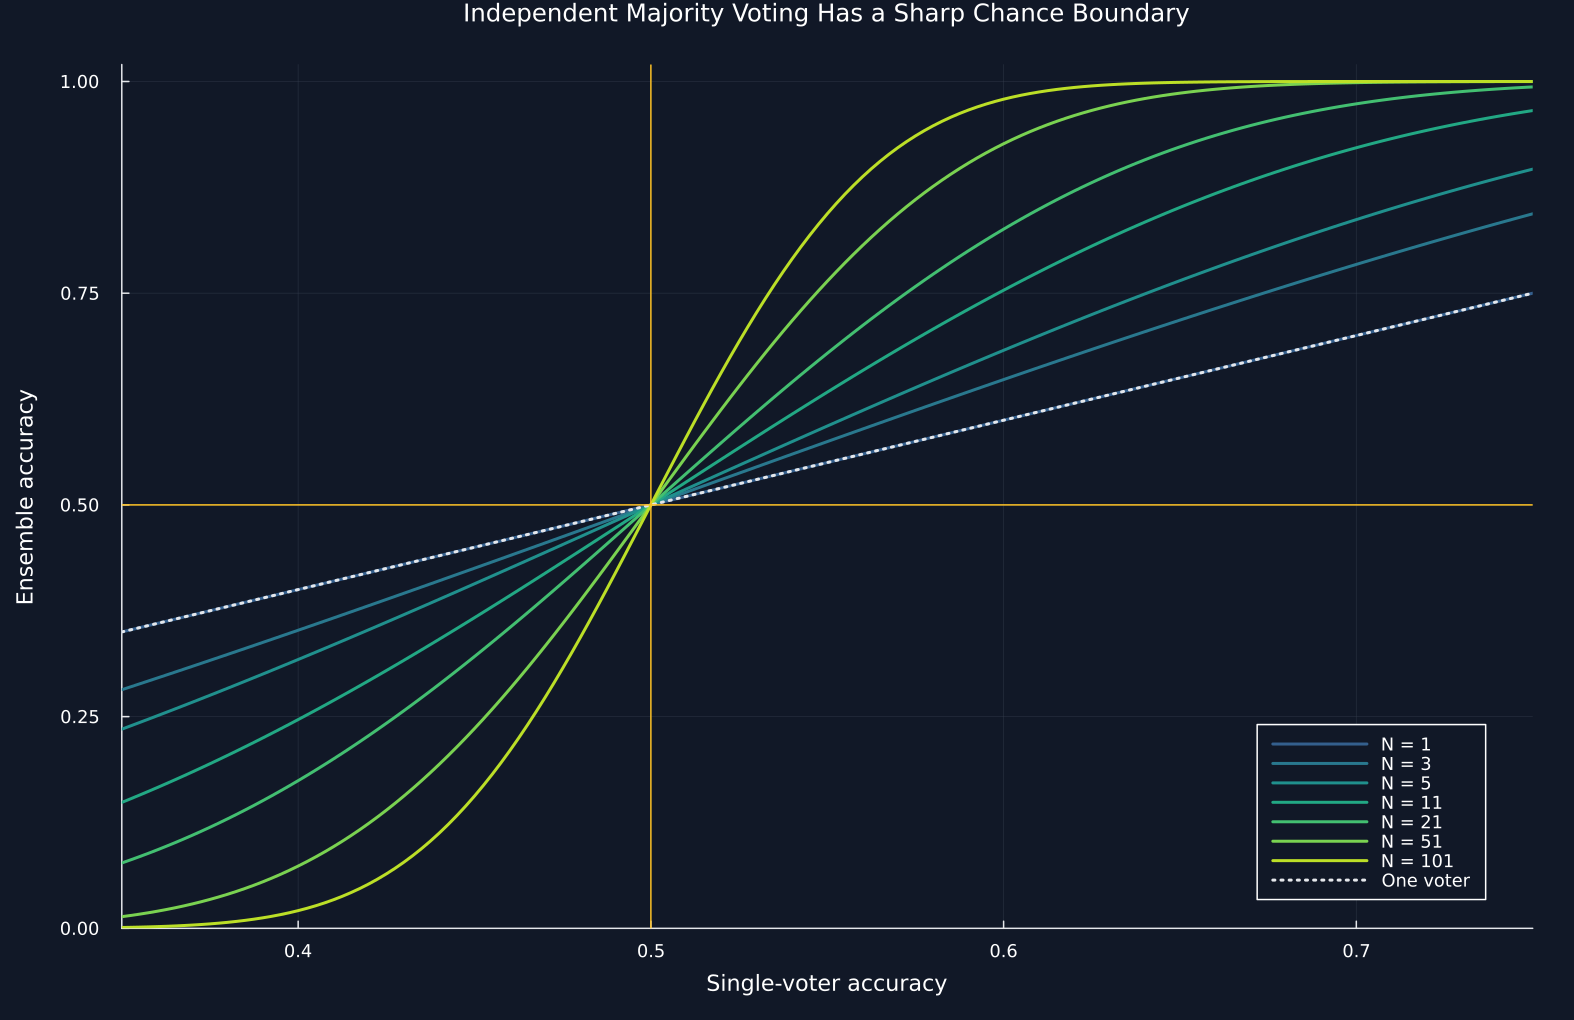

In [2]:
data_provenance = DataFrame("Field"=>["Archive","Provider","Provider database vintage","Return type","Analysis start","Analysis end","Daily observations","Industry portfolios"],"Value"=>["49_Industry_Portfolios_daily_CSV.zip","Kenneth R. French Data Library","202608 CRSP database","Daily value-weighted return",string(first(industry_dates)),string(last(industry_dates)),"1,760",string(size(industry_returns,2))])
table(data_provenance,"data_provenance","Fixed public observations used in Chapter 13.")
voter_counts = [1,3,5,11,21,51,101]
probability_grid = collect(range(.35,.75;length=161))
independent_curves = DataFrame([(Voters=voters,Probability=probability,Accuracy=bagging_classifier_accuracy(voters,probability)) for voters in voter_counts for probability in probability_grid])
rename!(independent_curves,:Probability=>"Single-voter accuracy",:Accuracy=>"Ensemble accuracy")
reported_probabilities = [.40,.50,.55,.60,.70]
independent_accuracy = DataFrame([(Voters=voters,Probability=probability,Accuracy=bagging_classifier_accuracy(voters,probability),Change=bagging_classifier_accuracy(voters,probability)-probability) for voters in voter_counts for probability in reported_probabilities])
rename!(independent_accuracy,:Probability=>"Single-voter accuracy",:Accuracy=>"Ensemble accuracy")
table(independent_accuracy[in.(independent_accuracy.Voters,Ref([1,11,101])),:],"independent_accuracy","Independent majority-vote accuracy for selected voter counts and individual accuracies.")
save_data(independent_curves,paths,"independent_curves")
save_data(independent_accuracy,paths,"independent_accuracy_all")
figure = plot(;title="Independent Majority Voting Has a Sharp Chance Boundary",xlabel="Single-voter accuracy",ylabel="Ensemble accuracy",xlims=(.35,.75),ylims=(0,1.02),legend=:bottomright,size=(1050,680))
for (index,voters) in enumerate(voter_counts)
    current = independent_curves[independent_curves.Voters.==voters,:]
    plot!(figure,current[!,"Single-voter accuracy"],current[!,"Ensemble accuracy"];color=cgrad(:viridis)[.25+.7(index-.5)/length(voter_counts)],label="N = $voters")
end
plot!(figure,probability_grid,probability_grid;color=palette.text,linestyle=:dot,label="One voter")
vline!(figure,[.5];color=palette.amber,linewidth=1,label=false)
hline!(figure,[.5];color=palette.amber,linewidth=1,label=false)
save_figure(figure,paths,"independent_majority_accuracy");


Equal positive dependence leaves a common variance floor and makes $N$ voters behave like a smaller independent ensemble:

$$
\operatorname{Var}(\overline Z_N)
=\sigma^2\!\left(\rho+\frac{1-\rho}{N}\right),
\qquad
N_{\mathrm{eff}}=\frac{N}{1+(N-1)\rho}.
$$

Here, $Z_i$ is voter $i$'s numerical output; $\overline Z_N=N^{-1}\sum_i Z_i$ is their mean; $\sigma^2$ is each output's variance. $\rho$ is the common pairwise correlation; $N$ is the stated voter count; $N_{\mathrm{eff}}$ is the independent-equivalent count; $\operatorname{Var}$ denotes variance.

## How dependence reduces effective ensemble size

A shared random success chance creates exchangeable correct votes whose mean is $p$ and whose pairwise correlation is $\rho.$:

$$
\Theta\sim\operatorname{Beta}(\alpha,\beta),
\qquad
K\mid\Theta\sim\operatorname{Binomial}(N,\Theta),
\qquad
\alpha=p(\rho^{-1}-1),
\quad
\beta=(1-p)(\rho^{-1}-1).
$$

Here, $\Theta$ is the shared success chance for one repetition; $\operatorname{Beta}(\alpha,\beta)$ is its distribution; $\alpha,\beta$ are shape parameters. $K$ is the number of correct votes among $N$; $p$ is mean voter accuracy; $\rho\in(0,1)$ is correct-vote correlation; the case $\rho=0$ is simulated independently.

Row,Voters,Correct-vote correlation,Majority accuracy,Effective voters
,Int64,Float64,Float64,Float64
1,1,0.0,0.5973,1.0
2,3,0.0,0.6461,3.0
3,5,0.0,0.681225,5.0
4,11,0.0,0.75285,11.0
5,21,0.0,0.824313,21.0
6,51,0.0,0.92615,51.0
7,101,0.0,0.978662,101.0
8,1,0.05,0.597313,1.0
9,3,0.05,0.64185,2.72727


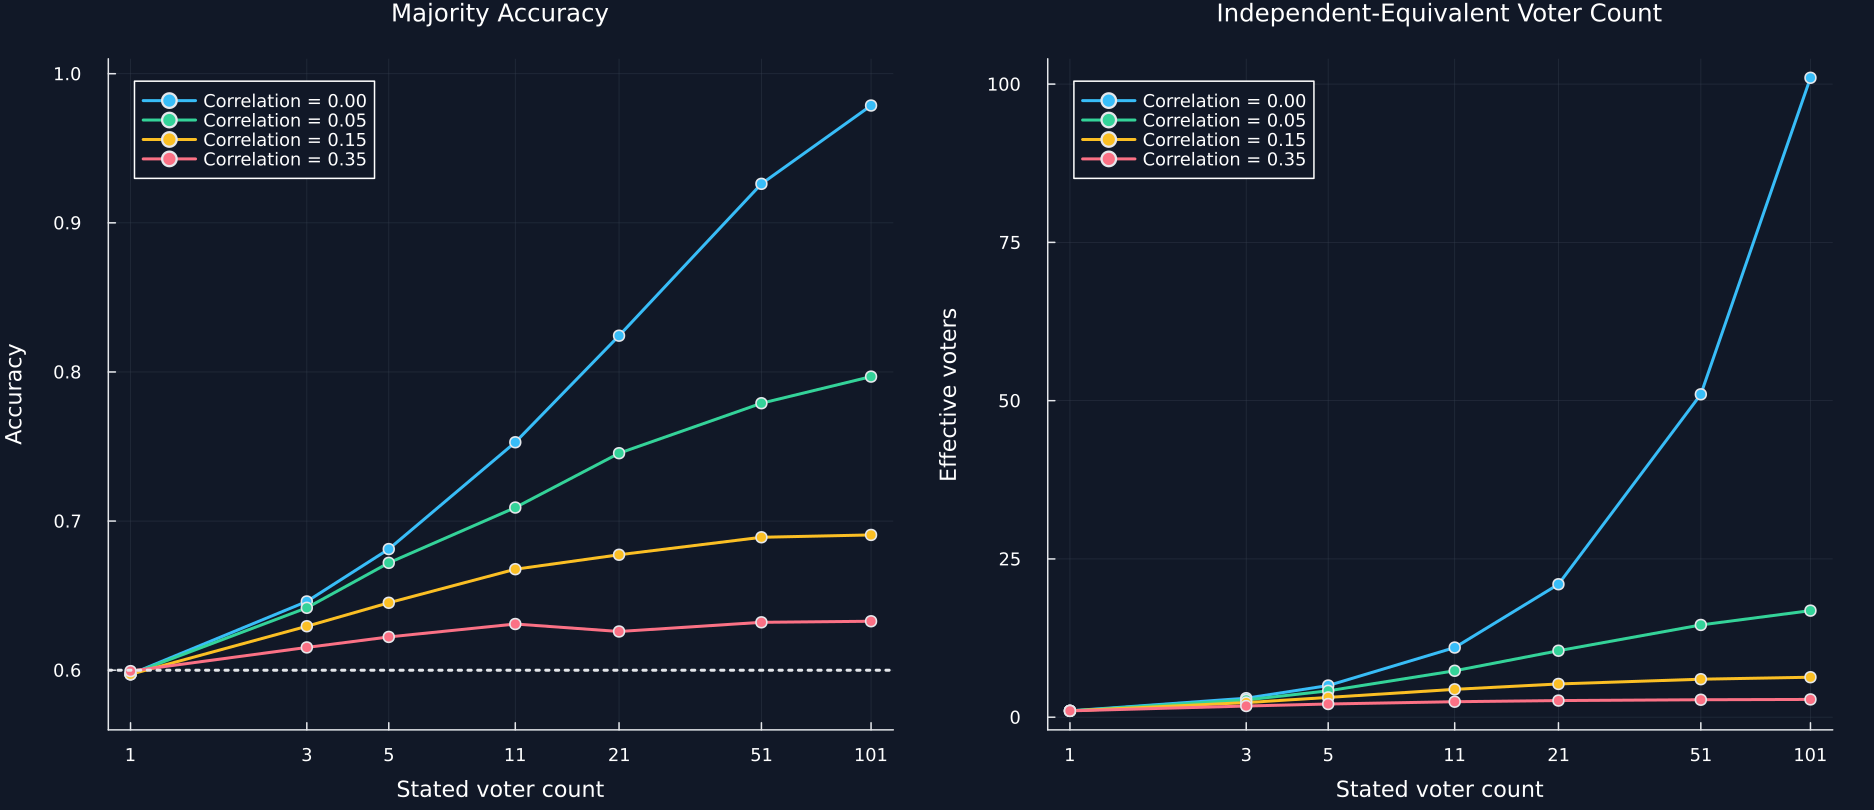

In [3]:
controlled_paths,controlled_p = 80000,.60
dependence_levels = [0.,.05,.15,.35]
correct_votes = Matrix{Int}(primitive("controlled_correct_votes"))
controlled_rows = NamedTuple[]
for (rho_index,dependence) in enumerate(dependence_levels),(voter_index,voters) in enumerate(voter_counts)
    votes = correct_votes[:,(rho_index-1)*length(voter_counts)+voter_index]
    @assert all(0 .<=votes.<=voters)
    push!(controlled_rows,(Voters=voters,Dependence=dependence,Accuracy=mean(votes.>fld(voters,2)),Effective=voters/(1+(voters-1)*dependence)))
end
controlled_dependence = DataFrame(controlled_rows)
rename!(controlled_dependence,:Dependence=>"Correct-vote correlation",:Accuracy=>"Majority accuracy",:Effective=>"Effective voters")
table(controlled_dependence,"controlled_dependence","Known-truth majority accuracy under exchangeable vote dependence.")
panels = [plot(;title="Majority Accuracy",xlabel="Stated voter count",ylabel="Accuracy",xscale=:log10,xticks=(voter_counts,string.(voter_counts)),ylims=(.56,1.01),legend=:topleft),plot(;title="Independent-Equivalent Voter Count",xlabel="Stated voter count",ylabel="Effective voters",xscale=:log10,xticks=(voter_counts,string.(voter_counts)),legend=:topleft)]
for (color,dependence) in zip([palette.cyan,palette.green,palette.amber,palette.rose],dependence_levels)
    current = controlled_dependence[controlled_dependence[!,"Correct-vote correlation"].==dependence,:]
    for (panel,column) in zip(panels,["Majority accuracy","Effective voters"])
        plot!(panel,current.Voters,current[!,column];color,marker=:circle,label=@sprintf("Correlation = %.2f",dependence))
    end
end
hline!(panels[1],[controlled_p];color=palette.text,linestyle=:dot,label=false)
save_figure(plot(panels...;layout=(1,2),size=(1250,540)),paths,"controlled_dependence_effect");


## Public Industry Voting

Each tree casts a signed binary vote, and the released calculation compares equal, training-accuracy, and $1-c_i^2$ weights:

$$
\begin{gathered}
\widehat y(x;w)
=\mathbf 1\!\left\{\sum_{i=1}^{N}w_i(2\widehat y_i(x)-1)>0\right\},
\qquad
\sum_{i=1}^{N}w_i=1,\\
w_i^{(u)}=\frac1N,
\qquad
w_i^{(c)}=\frac{c_i}{\sum_j c_j},
\qquad
w_i^{(v)}=\frac{1-c_i^2}{\sum_j(1-c_j^2)}.
\end{gathered}
$$

Here, $x$ is a feature vector; $\widehat y_i(x)\in\{0,1\}$ is tree $i$'s vote; $w_i$ is its nonnegative weight; $N$ is the number of trees. $\widehat y(x;w)$ is the combined prediction; $\mathbf 1\{\cdot\}$ is the indicator; $c_i$ is tree $i$'s training accuracy; superscripts $u,c,v$ name the three rules.

Row,Quantity,Value
,String,String
1,Usable dates,1755
2,Predictors,12
3,Lookback days,5
4,Forecast step,1
5,Training dates,1228
6,Test dates,527
7,Training end,2023-11-22
8,Test start,2023-11-24
9,Positive target share,0.5316239316239316


Row,Weight rule,Test accuracy,Minimum weight,Maximum weight,Mean tree training accuracy,Mean correctness correlation,Effective trees
,String,Float64,Float64,Float64,Float64,Float64,Float64
1,Uniform,0.502846,0.00990099,0.00990099,0.670881,0.0217684,31.7926
2,Training accuracy,0.502846,0.00947024,0.0102755,0.670881,0.0217684,31.7926
3,One minus squared accuracy,0.502846,0.00927877,0.0105934,0.670881,0.0217684,31.7926


Row,Trees,Mean accuracy,Tenth percentile,Ninetieth percentile
,Int64,Float64,Float64,Float64
1,1,0.500348,0.466414,0.527514
2,3,0.498039,0.472296,0.523719
3,5,0.494655,0.472296,0.518027
4,11,0.498419,0.476091,0.520114
5,21,0.496711,0.476091,0.518027
6,51,0.493707,0.472486,0.510436
7,101,0.502846,0.502846,0.502846


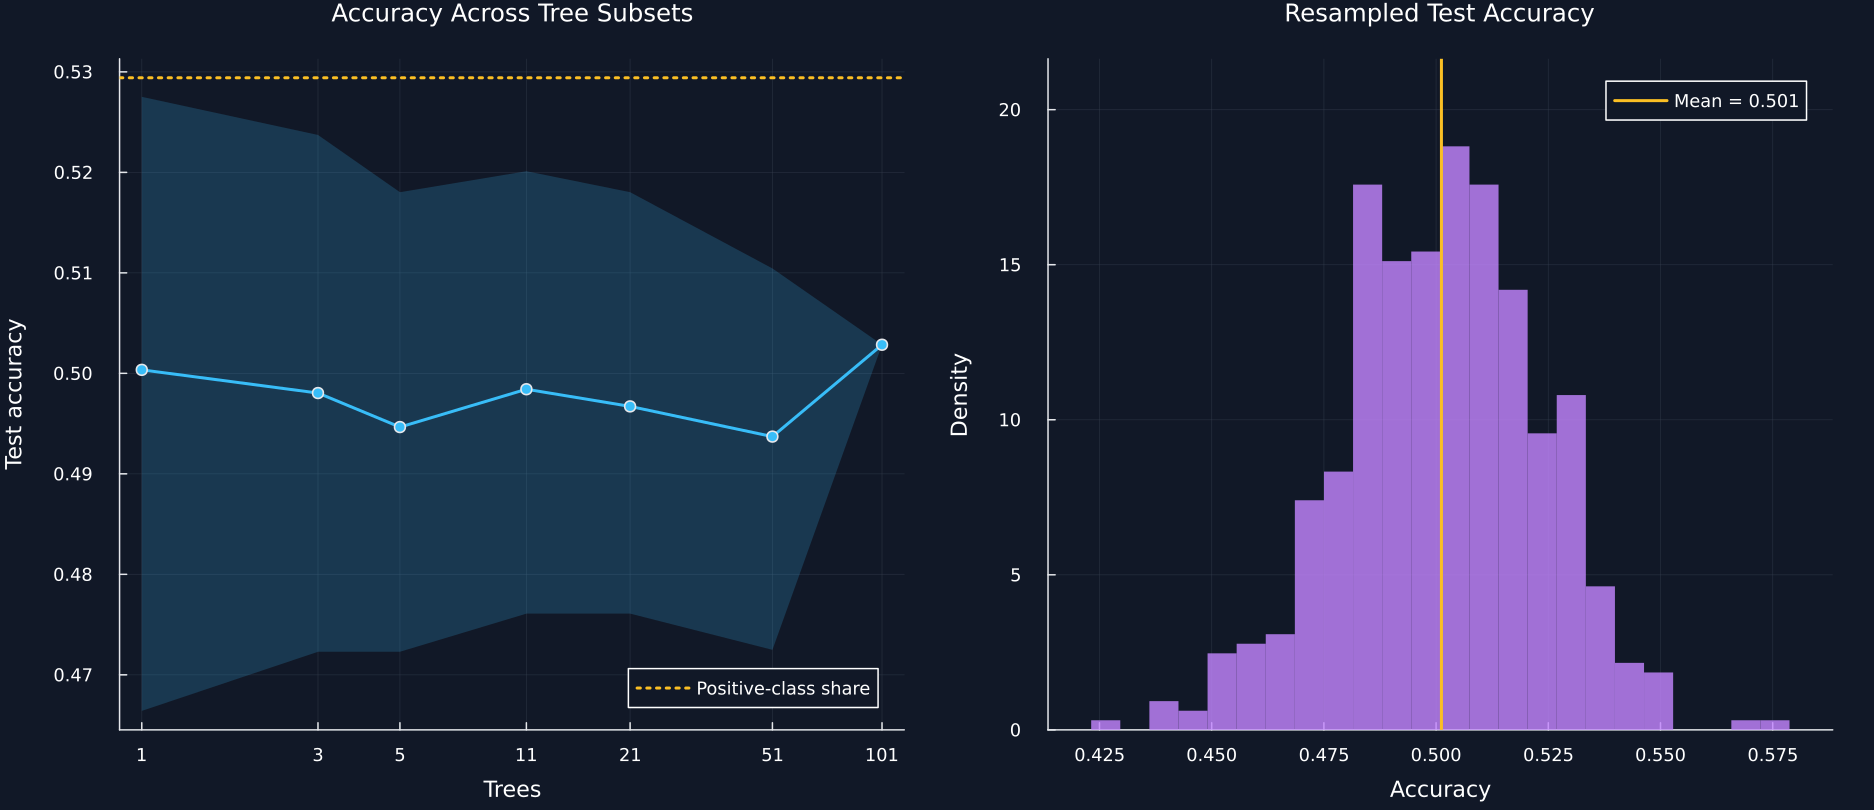

In [4]:
public_task_summary = DataFrame("Quantity"=>["Usable dates","Predictors","Lookback days","Forecast step","Training dates","Test dates","Training end","Test start","Positive target share"],"Value"=>string.([length(public_y),size(public_x,2),5,1,length(public_y_train),length(public_y_test),public_dates[split_index],public_dates[split_index+1],mean(public_y)]))
table(public_task_summary,"public_task_summary","Time-ordered public industry prediction task.")
fitted_bagging = Ref{Any}()
function fit_entropy(_,x,y,weights)
    @assert weights===nothing
    plan = Matrix{Int}(primitive("public_bagging_plan"))
    @assert all(vec(sum(plan[3:end,:];dims=1)).==500)
    balanced = [length(y)/(2count(==(value),y)) for value in y]
    trees = [BookEntropyForest.fit_tree(x,y,plan[3:end,index].*balanced,plan[2,index];max_features=1) for index in axes(plan,2)]
    fitted_bagging[] = trees
    nodes = [(tree=tree_index,node=index,feature=node.feature,threshold=node.threshold,left=node.left,right=node.right,count=node.count,mass=node.mass,negative=node.negative_mass,positive=node.positive_mass,impurity=node.impurity) for (tree_index,tree) in enumerate(trees) for (index,node) in enumerate(tree.nodes)]
    save_data(DataFrame(nodes),paths,"public_bagging_nodes")
    return trees
end
tree_predictions(trees,x) = hcat([BookEntropyForest.predict(tree,x) for tree in trees]...)
public_accuracies = bagging_evaluate_schemes(nothing,public_x_train,public_y_train,public_x_test,public_y_test;fit_estimator=fit_entropy,tree_predictions,estimator_classes=_->[0,1])
trees = fitted_bagging[]
training_predictions = tree_predictions(trees,public_x_train)
public_tree_predictions = tree_predictions(trees,public_x_test)
tree_training_accuracy = vec(mean(training_predictions.==public_y_train;dims=1))
weights = RiskLabAI.Ensemble._bagging_member_weights(training_predictions,public_y_train)
probabilities = [BookEntropyForest.predict_proba(tree,public_x) for tree in trees]
probability_records = [(tree=tree,row=row,p0=values[row,1],p1=values[row,2]) for (tree,values) in enumerate(probabilities) for row in axes(values,1)]
save_data(DataFrame(probability_records),paths,"public_bagging_probabilities")
save_data(hcat(DataFrame(date=public_dates,target=public_y),DataFrame(public_x,selected_features)),paths,"public_predictors")
save_data(DataFrame(tree=1:101,accuracy=tree_training_accuracy,uniform=weights["uniform"],c_i=weights["c_i"],variance=weights["variance"]),paths,"public_tree_scores")
public_tree_correct = Float64.(public_tree_predictions.==public_y_test)
correct_correlation = cor(public_tree_correct)
finite_pairwise = filter(isfinite,upper_values(correct_correlation))
mean_correct_correlation = mean(finite_pairwise)
effective_public_trees = 101/(1+100mean_correct_correlation)
public_ensemble_summary = DataFrame("Weight rule"=>["Uniform","Training accuracy","One minus squared accuracy"],"Test accuracy"=>[public_accuracies[key] for key in ["uniform","c_i","variance"]],"Minimum weight"=>[minimum(weights[key]) for key in ["uniform","c_i","variance"]],"Maximum weight"=>[maximum(weights[key]) for key in ["uniform","c_i","variance"]],"Mean tree training accuracy"=>fill(mean(tree_training_accuracy),3),"Mean correctness correlation"=>fill(mean_correct_correlation,3),"Effective trees"=>fill(effective_public_trees,3))
table(public_ensemble_summary,"public_ensemble_summary","Public voting results and dependence summary.")
subsets = Matrix{Int}(primitive("tree_subsets"))
curve_rows,subset_records = NamedTuple[],NamedTuple[]
for voters in voter_counts
    repeated_accuracy = Float64[]
    for plan in eachrow(subsets[subsets[:,1].==voters,:])
        chosen = plan[3:voters+2]
        majority = Int.(vec(sum(public_tree_predictions[:,chosen];dims=2)).>fld(voters,2))
        push!(repeated_accuracy,mean(majority.==public_y_test))
        push!(subset_records,(voters=voters,repetition=plan[2],accuracy=last(repeated_accuracy)))
    end
    push!(curve_rows,(Trees=voters,Mean=mean(repeated_accuracy),Lower=quantile(repeated_accuracy,.1),Upper=quantile(repeated_accuracy,.9)))
end
public_ensemble_curve = DataFrame(curve_rows)
rename!(public_ensemble_curve,:Mean=>"Mean accuracy",:Lower=>"Tenth percentile",:Upper=>"Ninetieth percentile")
table(public_ensemble_curve,"public_ensemble_curve","Public uniform-vote accuracy over repeated subsets of fitted trees.")
save_data(DataFrame(subset_records),paths,"public_subset_accuracy")
mean_probabilities = zeros(size(public_x,1),2)
for probability in probabilities
    mean_probabilities .+= probability
end
mean_probabilities ./=length(trees)
soft_predictions = [argmax(row)-1 for row in eachrow(mean_probabilities[split_index+1:end,:])]
prediction_cache = Dict(Tuple(public_x_test[row,:])=>soft_predictions[row] for row in axes(public_x_test,1))
@assert length(prediction_cache)==length(public_y_test)
bootstraps = Matrix{Int}(primitive("test_bootstrap"))
bootstrap_accuracy,bootstrap_mean,bootstrap_std = calculate_bootstrap_accuracy(prediction_cache,public_x_test,public_y_test;predict=(cache,x)->[cache[Tuple(row)] for row in eachrow(x)],n_bootstraps=500,bootstrap_rows=[bootstraps[:,index] for index in axes(bootstraps,2)])
save_data(DataFrame(accuracy=bootstrap_accuracy),paths,"public_bootstrap_accuracy")
save_data(DataFrame(p0=mean_probabilities[split_index+1:end,1],p1=mean_probabilities[split_index+1:end,2],prediction=soft_predictions),paths,"public_bagging_mean_probability")
curve = public_ensemble_curve
first_panel = plot(curve.Trees,curve[!,"Mean accuracy"];ribbon=(curve[!,"Mean accuracy"].-curve[!,"Tenth percentile"],curve[!,"Ninetieth percentile"].-curve[!,"Mean accuracy"]),fillalpha=.2,color=palette.cyan,marker=:circle,label=false,xscale=:log10,xticks=(voter_counts,string.(voter_counts)),title="Accuracy Across Tree Subsets",xlabel="Trees",ylabel="Test accuracy",legend=:bottomright)
hline!(first_panel,[mean(public_y_test)];color=palette.amber,linestyle=:dot,label="Positive-class share")
second_panel = histogram(bootstrap_accuracy;bins=histogram_edges(bootstrap_accuracy,24,"public_bootstrap";density=true),normalize=:pdf,color=violet,linealpha=0,alpha=.82,label=false,title="Resampled Test Accuracy",xlabel="Accuracy",ylabel="Density")
vline!(second_panel,[bootstrap_mean];color=palette.amber,label=@sprintf("Mean = %.3f",bootstrap_mean))
ylims!(second_panel,(0,1.15last(ylims(second_panel))))
save_figure(plot(first_panel,second_panel;layout=(1,2),size=(1250,540)),paths,"public_bagging_accuracy");


## Individual Tree Accuracy

The training accuracy of one tree is the share of training observations it classifies correctly:

$$
c_i=\frac{1}{T}\sum_{t=1}^{T}\mathbf 1\{\widehat y_{i,t}=y_t\}.
$$

Here, $i$ identifies a tree; $t$ identifies a training observation; $T$ is the training sample size. $\widehat y_{i,t}$ is tree $i$'s prediction for observation $t$; $y_t$ is the observed class; $\mathbf 1\{\cdot\}$ equals one when the prediction is correct; $c_i$ is tree accuracy.

Row,Summary,Training accuracy
,String,Float64
1,Smallest,0.641694
2,10th percentile,0.655537
3,25th percentile,0.664495
4,Middle value,0.670195
5,Mean,0.670881
6,75th percentile,0.679153
7,90th percentile,0.685668
8,Largest,0.696254
9,Standard deviation,0.0118136


Row,Group,Tree number,Training accuracy
,String,Int64,Float64
1,Five smallest,33,0.641694
2,Five smallest,1,0.642508
3,Five smallest,15,0.645765
4,Five smallest,28,0.645765
5,Five smallest,51,0.648208
6,Five largest,21,0.691368
7,Five largest,17,0.692182
8,Five largest,99,0.692997
9,Five largest,87,0.693811


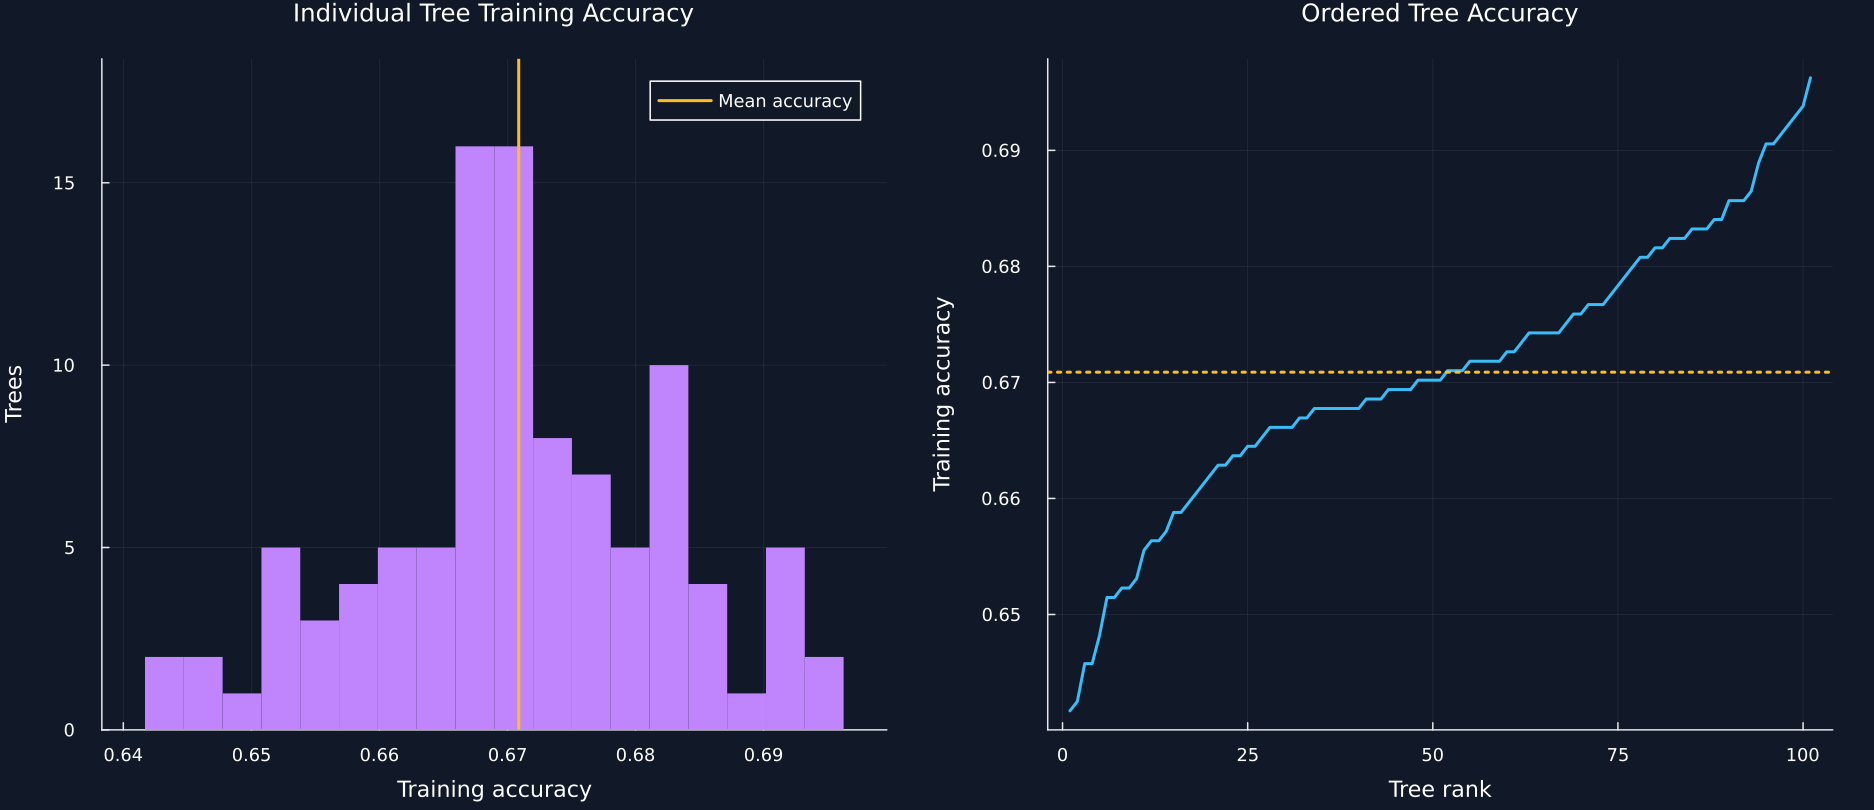

In [5]:
tree_accuracy_summary = DataFrame("Summary"=>["Smallest","10th percentile","25th percentile","Middle value","Mean","75th percentile","90th percentile","Largest","Standard deviation"],"Training accuracy"=>[minimum(tree_training_accuracy),quantile(tree_training_accuracy,.1),quantile(tree_training_accuracy,.25),median(tree_training_accuracy),mean(tree_training_accuracy),quantile(tree_training_accuracy,.75),quantile(tree_training_accuracy,.9),maximum(tree_training_accuracy),std(tree_training_accuracy)])
ordering = sortperm(tree_training_accuracy)
ranked_tree_accuracy = DataFrame("Tree number"=>ordering,"Training accuracy"=>tree_training_accuracy[ordering])
tree_accuracy_extremes = vcat(hcat(DataFrame(Group=fill("Five smallest",5)),ranked_tree_accuracy[1:5,:]),hcat(DataFrame(Group=fill("Five largest",5)),ranked_tree_accuracy[end-4:end,:]))
table(tree_accuracy_summary,"tree_training_accuracy_summary","Distribution of individual-tree training accuracy.")
table(tree_accuracy_extremes,"tree_training_accuracy_extremes","Trees with the five smallest and five largest training accuracies.")
save_data(ranked_tree_accuracy,paths,"ranked_tree_accuracy")
first_panel = histogram(tree_training_accuracy;bins=histogram_edges(tree_training_accuracy,18,"tree_training"),color=violet,linealpha=0,label=false,title="Individual Tree Training Accuracy",xlabel="Training accuracy",ylabel="Trees")
vline!(first_panel,[mean(tree_training_accuracy)];color=palette.amber,label="Mean accuracy")
ylims!(first_panel,(0,1.15last(ylims(first_panel))))
second_panel = plot(1:101,ranked_tree_accuracy[!,"Training accuracy"];color=palette.cyan,title="Ordered Tree Accuracy",xlabel="Tree rank",ylabel="Training accuracy",label=false)
hline!(second_panel,[mean(tree_training_accuracy)];color=palette.amber,linestyle=:dot,label=false)
save_figure(plot(first_panel,second_panel;layout=(1,2),size=(1250,540)),paths,"tree_training_accuracy");


## Tests

In [6]:
@assert size(industry_returns)==(1760,49)
@assert size(data_provenance)==(8,2)
@assert size(public_x)==(1755,12)
@assert length(public_y_train)==1228
@assert length(public_y_test)==527
@assert public_dates[split_index]<public_dates[split_index+1]
@assert all(in((0,1)),public_y)
@assert bagging_classifier_accuracy(1,.7)≈.7
@assert bagging_classifier_accuracy(3,.7)≈.784
@assert bagging_classifier_accuracy(101,.5)≈.5
@assert bagging_classifier_accuracy(101,.6)>.97
@assert bagging_classifier_accuracy(101,.4)<.03
@assert size(independent_accuracy)==(35,4)
@assert size(controlled_dependence)==(28,4)
@assert all(0 .<=controlled_dependence[!,"Majority accuracy"].<=1)
@assert all(controlled_dependence[!,"Effective voters"].>=1)
@assert controlled_dependence[7,"Majority accuracy"]>.97
@assert controlled_dependence[28,"Majority accuracy"]<.70
@assert controlled_dependence[28,"Effective voters"]<3
@assert Set(keys(public_accuracies))==Set(["uniform","c_i","variance"])
@assert all(value->0<=value<=1,values(public_accuracies))
@assert size(public_tree_predictions)==(527,101)
@assert length(tree_training_accuracy)==101
@assert all(value->sum(value)≈1,values(weights))
@assert isfinite(mean_correct_correlation)
@assert 0<effective_public_trees<=101
@assert size(public_ensemble_summary)==(3,7)
@assert size(public_ensemble_curve)==(7,4)
@assert all(curve[!,"Tenth percentile"].<=curve[!,"Mean accuracy"].+1e-12)
@assert all(curve[!,"Mean accuracy"].<=curve[!,"Ninetieth percentile"].+1e-12)
@assert all(0 .<=tree_training_accuracy.<=1)
@assert size(tree_accuracy_summary)==(9,2)
@assert size(tree_accuracy_extremes)==(10,3)
@assert issorted(ranked_tree_accuracy[!,"Training accuracy"])
@assert length(bootstrap_accuracy)==500
@assert mean(bootstrap_accuracy)≈bootstrap_mean
@assert bootstrap_std>0
@assert size(correct_votes)==(80000,28)
@assert nrow(DataFrame(subset_records))==420
@assert length(trees)==101
@assert all(isfile(joinpath(paths.figures,name*".pdf")) for name in ["independent_majority_accuracy","controlled_dependence_effect","public_bagging_accuracy","tree_training_accuracy"])
@assert all(isfile(joinpath(paths.tables,name*".tex")) for name in ["data_provenance","independent_accuracy","controlled_dependence","public_ensemble_summary","public_ensemble_curve","tree_training_accuracy_summary","tree_training_accuracy_extremes"])
println("Native bagging, fixed dependent votes, weighted entropy trees, subsets and bootstrap assertions passed.");


Native bagging, fixed dependent votes, weighted entropy trees, subsets and bootstrap assertions passed.
